In [ ]:
'''
Let's see if I can inspect the df results but better this time
also fourier stuff is in here
'''

In [5]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

In [37]:
import plot_time_series as pts
import precision_recall as pr
import importlib
#importlib.reload(plot_time_series)
import gc #garbage collector
import glob #i don't know if there is a better way to do this but this was the 
#internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from scipy.signal import find_peaks

In [7]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [8]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

In [79]:
from scipy.fft import rfft, irfft, rfftfreq

In [11]:
#okay so now we should have a bunch of reduced dataframes

# Set the folder path where your DataFrames are stored
folder_path = '/lustre/lrspec/ZTF_data/science_extractions/1020'
direcname = '1020'
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"


# List all the files in the folder
files = [f for f in os.listdir(folder_path) if f.endswith('sobelratio')]  # Adjust this to your file format




    
# Step 3: Read all DataFrames and add the filename as a new column
dataframes = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    dataframes.append(df)

# Step 4: Concatenate all DataFrames into one
concatenated_df_sobel = pd.concat(dataframes, ignore_index=True)

# Display the concatenated DataFrame
concatenated_df_sobel

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio
0,0,34,34,ztf_20221020154120_000640_zi_c09_x_0017.,pos,173.500000,592.000000,6.0,4,22.759903
1,1,56,56,ztf_20221020154120_000640_zi_c09_x_0017.,pos,307.000000,592.000000,5.0,4,19.525473
2,2,71,71,ztf_20221020154120_000640_zi_c09_x_0017.,pos,399.076923,592.230769,13.0,4,12.377268
3,3,77,77,ztf_20221020154120_000640_zi_c09_x_0017.,pos,426.833333,592.166667,6.0,4,20.345509
4,4,85,85,ztf_20221020154120_000640_zi_c09_x_0017.,pos,463.000000,1751.833333,18.0,4,16.250433
...,...,...,...,...,...,...,...,...,...,...
614006,173,508,508,ztf_20221020138241_000686_zi_c15_x_0029.,both,2887.000000,523.000000,5.0,1,19.482388
614007,174,510,510,ztf_20221020138241_000686_zi_c15_x_0029.,both,2903.500000,523.250000,8.0,1,20.777689
614008,175,514,514,ztf_20221020138241_000686_zi_c15_x_0029.,both,2951.666667,523.333333,27.0,1,12.660818
614009,176,517,517,ztf_20221020138241_000686_zi_c15_x_0029.,both,2972.625000,523.375000,8.0,1,26.944208


In [12]:
nocrs = concatenated_df_sobel[concatenated_df_sobel['sobel_ratio']>5]

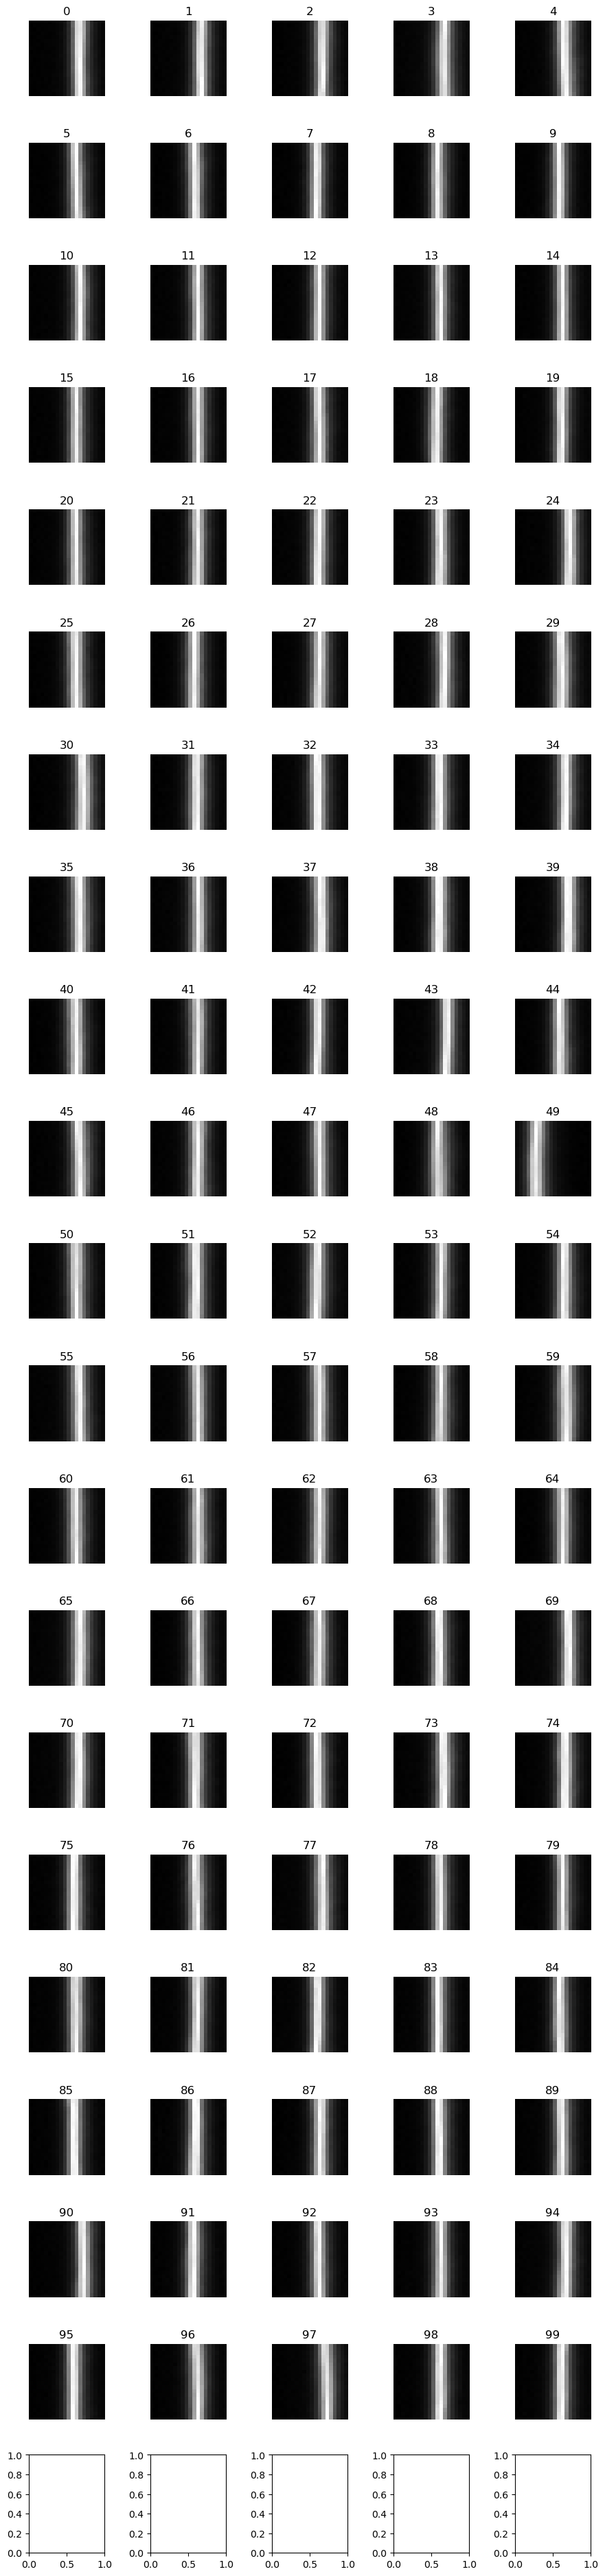

In [190]:
rff.inspect_df_with_quadrant(nocrs[:100], '1020')

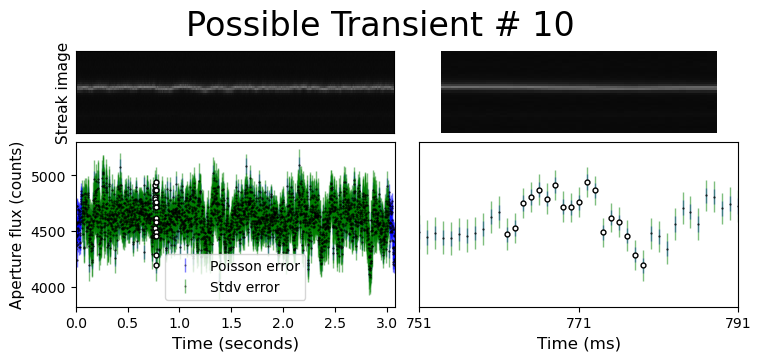

In [30]:
rff.plot_time_series_again_aperture(nocrs, 10, '1020', 2, tracking=True)

In [77]:
index = 10
fname = df.iloc[index]["filename"]+"fits.fz"
row = int(df.iloc[index]["row_from_nn"])
col = int(df.iloc[index]["col_from_nn"])
quad = int(df.iloc[index]["quadrant"])
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
path = fpath+fname
hdul = fits.open(path)
file1_array = hdul[1].data
header = fits.getheader(path)

In [106]:
def get_rfft_sq(index, direcname, df, half_aperture, tracking, plot=False, name="nocrs"):
    wideval = 2
    fname = df.iloc[index]["filename"]+"fits.fz"
    row = int(df.iloc[index]["row_from_nn"])+10
    col = int(df.iloc[index]["col_from_nn"])+10
    quad = int(df.iloc[index]["quadrant"])
    fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
    path = fpath+fname
    hdul=fits.open(path)
    image = hdul[quad].data
    column=col
    # image = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    
    
    background = rff.get_image_background(image)

   
    imagenobackground = image - np.full(np.shape(image),background)

    tot, maxcols = get_tot(df, index, direcname, half_aperture, tracking)
    
   

    sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
    Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
    N = len(tot)
    freqs = np.fft.rfftfreq(N, d=1/Fs)
    
    pixel_to_ms_factor = 1 / 0.6
    freqs_ms = freqs / pixel_to_ms_factor

    if plot==True:
        plt.plot(freqs_ms[1:], sqfft)
        plt.ylabel("Power")
        plt.xlabel("Frequency (KHz)") #cycles per millisecond
        plt.title("RFFT^2 of streak "+str(index)+" from df "+str(name))
        # plt.yscale("log")
    return sqfft, freqs_ms

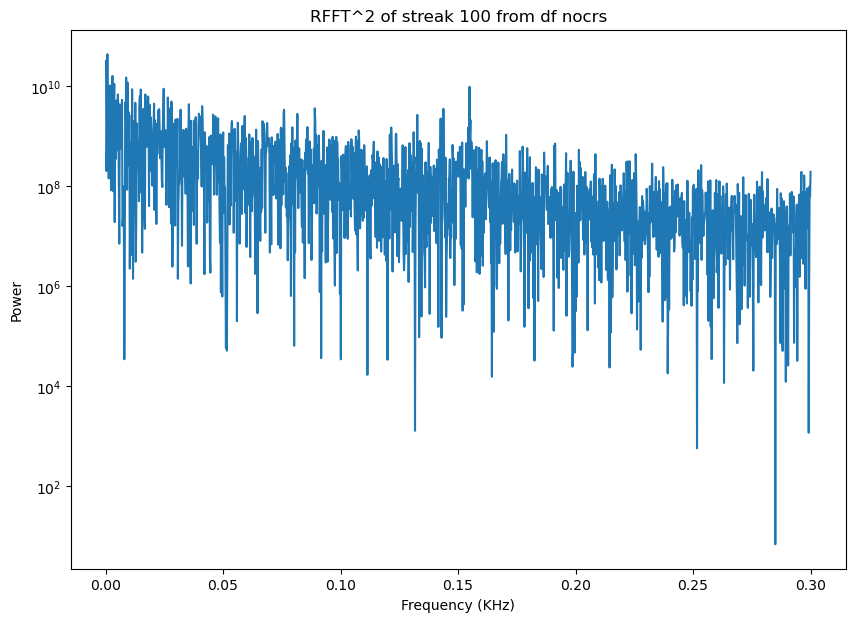

In [94]:
output_no, freqs_ms = get_rfft_sq(100, '1020', nocrs, half_aperture=2, tracking=True,  plot=True)


(0.1545, 0.155)

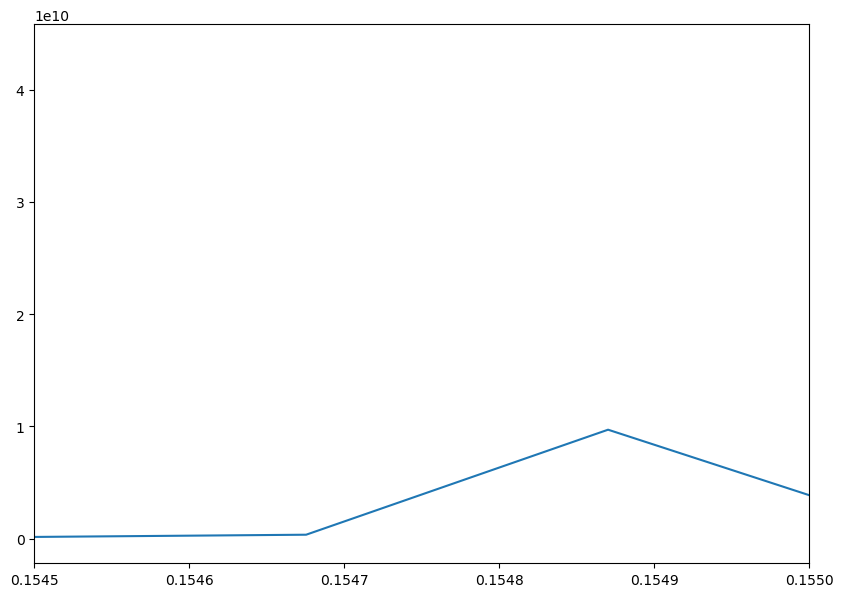

In [113]:
plt.plot(freqs_ms[1:], output_no)
plt.xlim(.1545,.155)

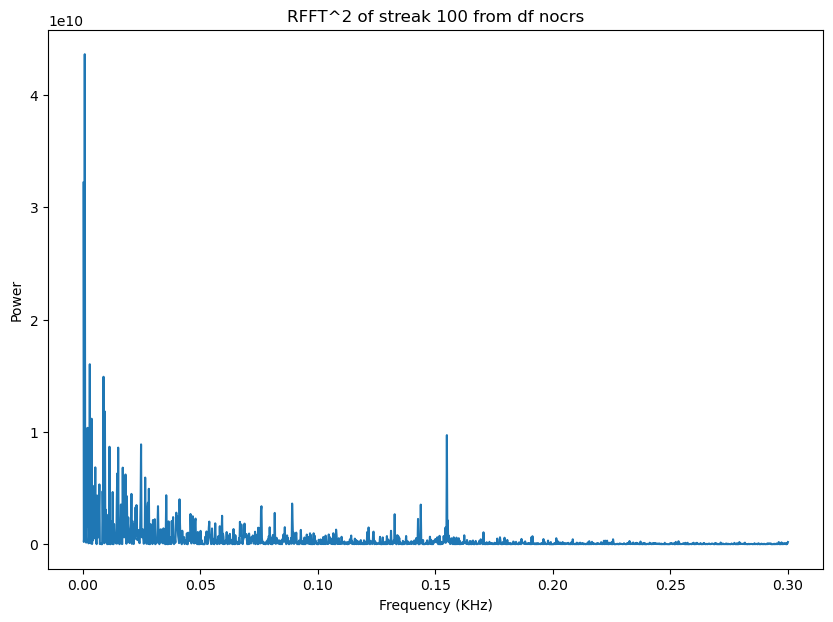

In [107]:
output_no, freqs_ms = get_rfft_sq(100, '1020', nocrs, half_aperture=2, tracking=True,  plot=True)


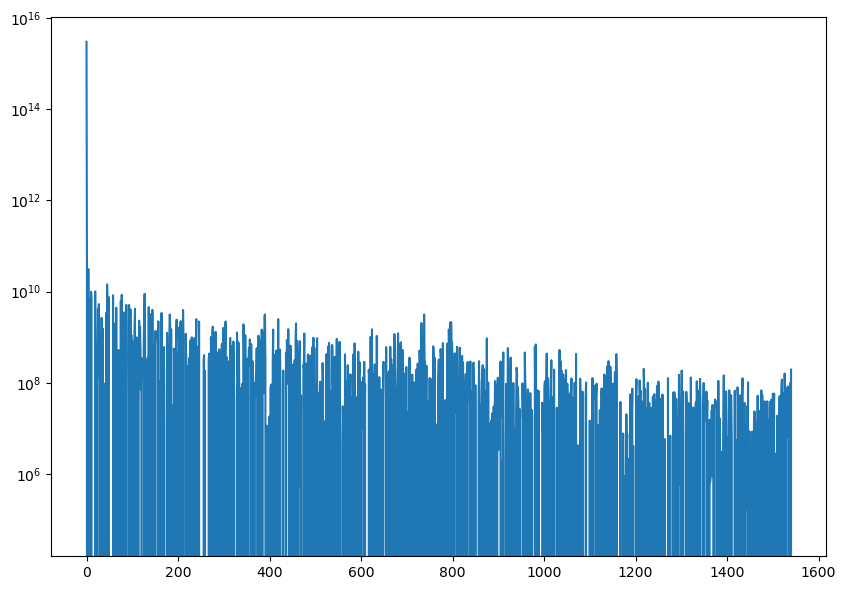

In [157]:


# Compute FFT and get frequencies
tot, maxcols = get_tot(nocrs,100, '1020',  half_aperture=2, tracking=True)




# Step 1: Compute FFT and get frequencies
Fs = 1  # Assuming pixel as unit for FFT frequency calculation
N = len(tot)
fft_vals = rfft(tot)
freqs = rfftfreq(N, d=1/Fs)

# Step 2: Convert frequencies to cycles per millisecond (mHz)
pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

# Step 3: Define Gaussian band-stop filter parameters in mHz
target_freq_ms = .1549  # Target frequency in cycles per ms (replace with your specific value)
sigma_ms = 0.0001  # Width of Gaussian in cycles per ms

# Gaussian band-stop filter in cycles per ms
gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms)**2)

# Step 4: Apply the filter to FFT values
filtered_fft_vals = fft_vals * gaussian_filter

# Step 5: Inverse FFT to get the filtered signal back in time domain
filtered_tot = irfft(filtered_fft_vals)

# Plot the original and filtered signals for comparison
# plt.plot(tot, label='Original Signal')
# plt.plot(filtered_tot, label='Filtered Signal', linestyle='--')
# plt.legend()
# plt.xlabel("Pixel Index")
# plt.ylabel("Flux")
# plt.title("Original vs. Gaussian-Filtered Signal")
# plt.show()

# plt.plot(filtered_fft_vals)
plt.plot(np.square(fft_vals))
plt.yscale("log")

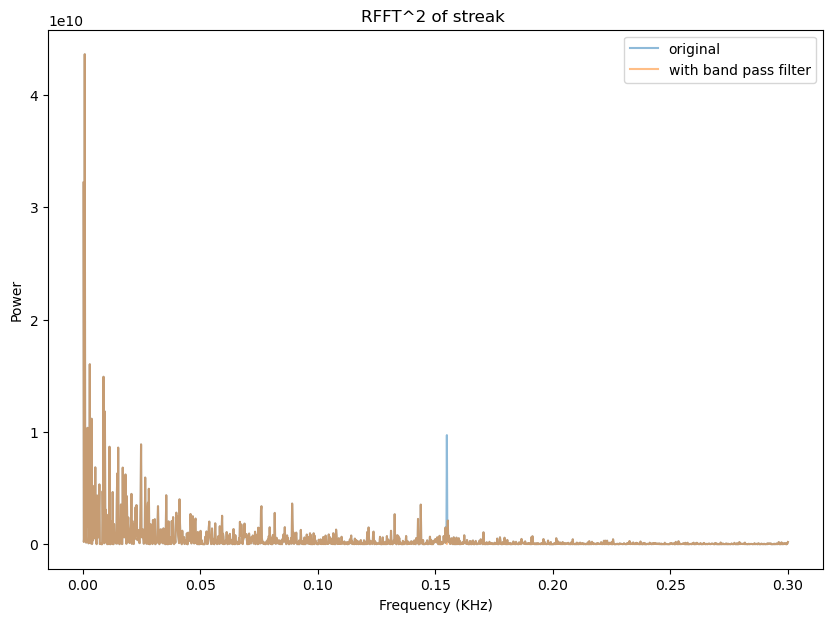

In [159]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1/Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label='with band pass filter', alpha=.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)") #cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

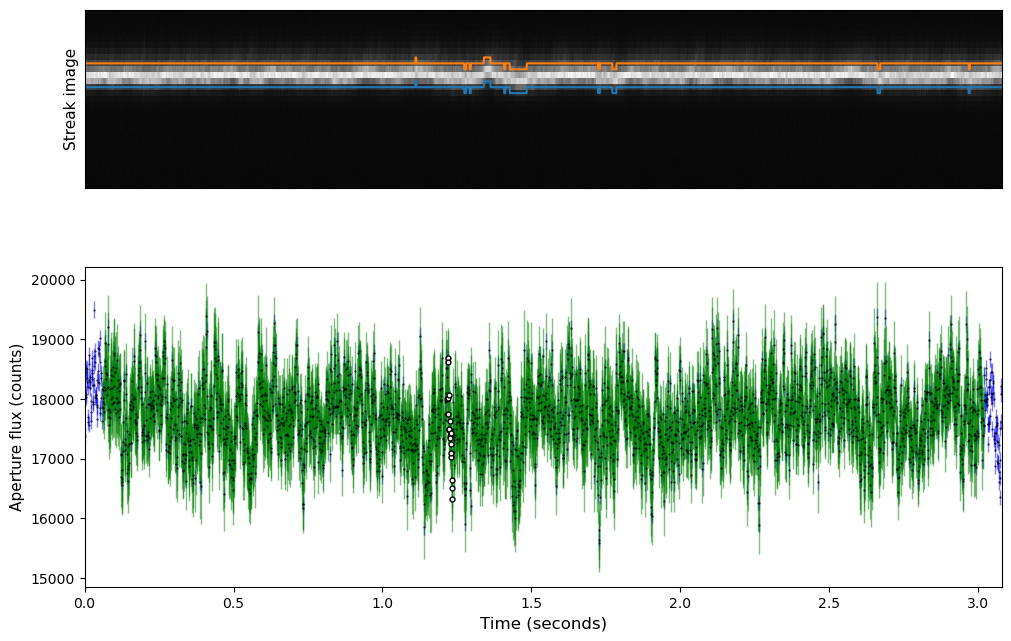

In [131]:

plot_tracking_options(df=nocrs, index=100, direcname='1020', half_aperture=2, tracking=True)

Text(0, 0.5, 'Flux')

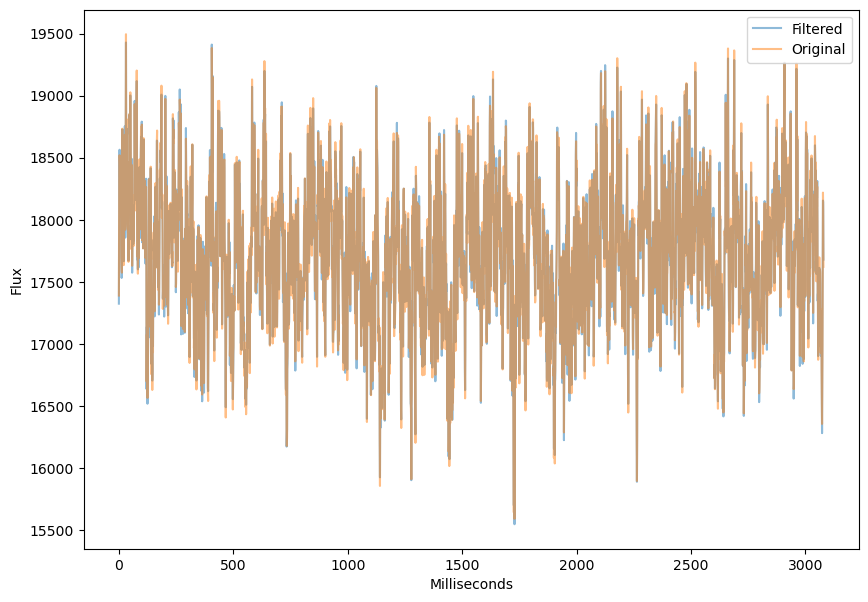

In [141]:
plt.plot(filtered_tot, alpha=.5, label="Filtered")
plt.plot(tot, alpha=.5, label="Original")
plt.legend()
plt.xlabel("Milliseconds")
plt.ylabel("Flux")

(1000.0, 1200.0)

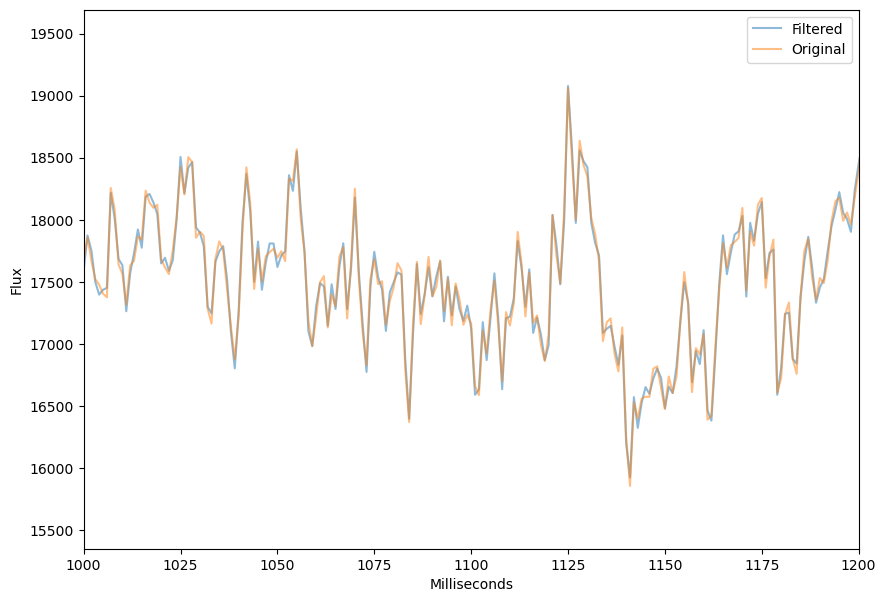

In [145]:
plt.plot(filtered_tot, alpha=.5, label="Filtered")
plt.plot(tot, alpha=.5, label="Original")
plt.legend()
plt.xlabel("Milliseconds")
plt.ylabel("Flux")
plt.xlim(1000,1200)

Text(0.5, 0, 'Frequency')

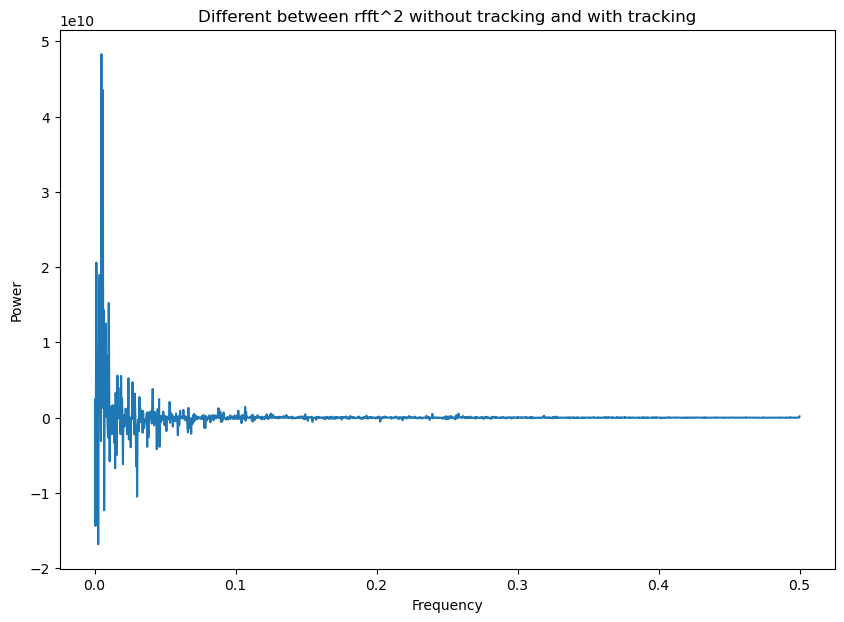

In [125]:
plt.plot(freqs[1:], output_no-output_w)
plt.title("Different between rfft^2 without tracking and with tracking")
plt.ylabel("Power")
plt.xlabel("Frequency")

(0.0, 100.0)

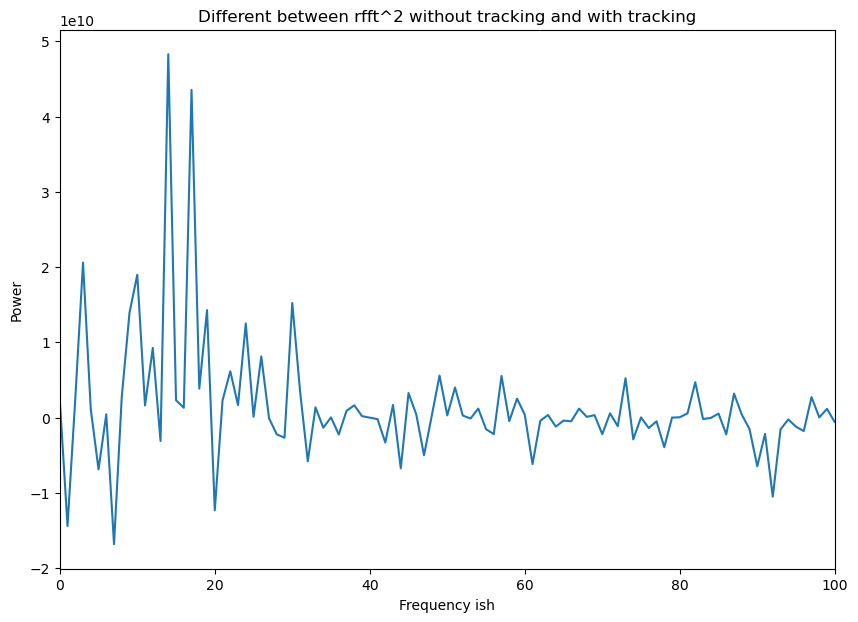

In [130]:
plt.plot(output_no-output_w)
plt.title("Different between rfft^2 without tracking and with tracking")
plt.ylabel("Power")
plt.xlabel("Frequency ish")
plt.xlim(0,100)

In [ ]:
'''
We shall quantify the change in standard deviation with tracking vs no tracking



'''

In [23]:
tot, maxcols = rff.get_tot(df=nocrs, index=100, direcname='1020', half_aperture=2, tracking=True)

In [25]:
np.average(tot)
stdv = rff.get_stdvs(tot, do_all=True, df=nocrs, index=100)
# plt.plot(stdv[61:-60])
print(np.average(tot), np.average(stdv[61:-60]))

17711.937728604404 525.3341813186044


In [24]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

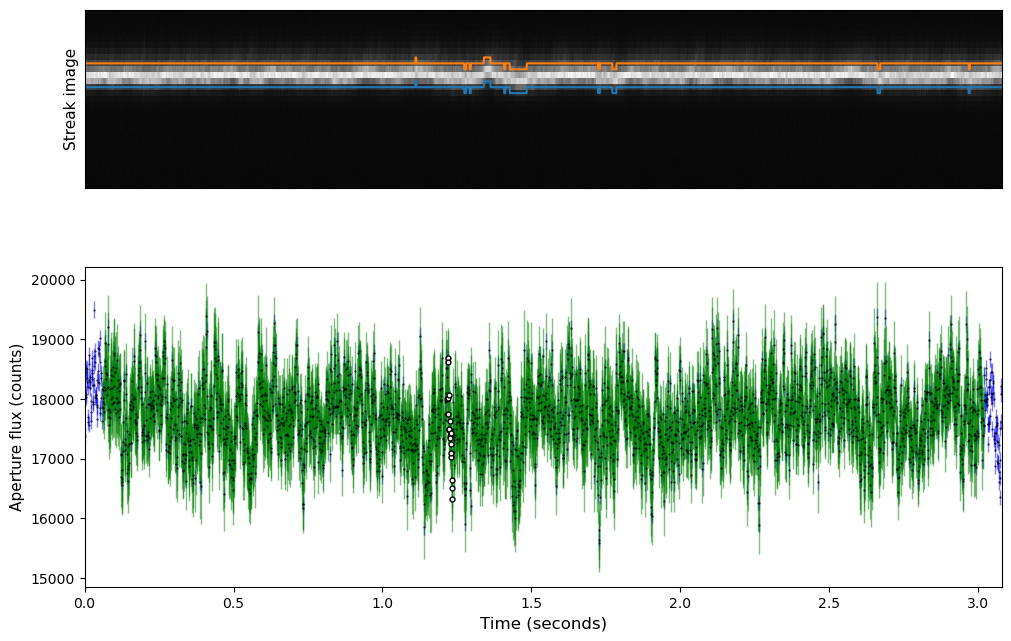

In [21]:
rff.plot_tracking_options(df=nocrs, index=100, direcname='1020', half_aperture=2, tracking=True)

In [129]:
tot2 = get_tot(nocrs, 10, '1020', half_aperture=2, tracking=False)

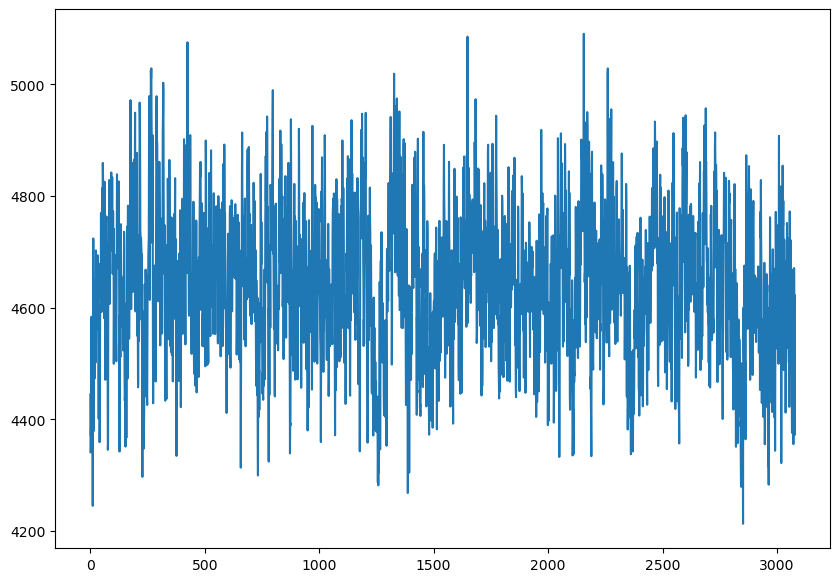

In [130]:
# plt.plot(tot1)
plt.plot(tot2)

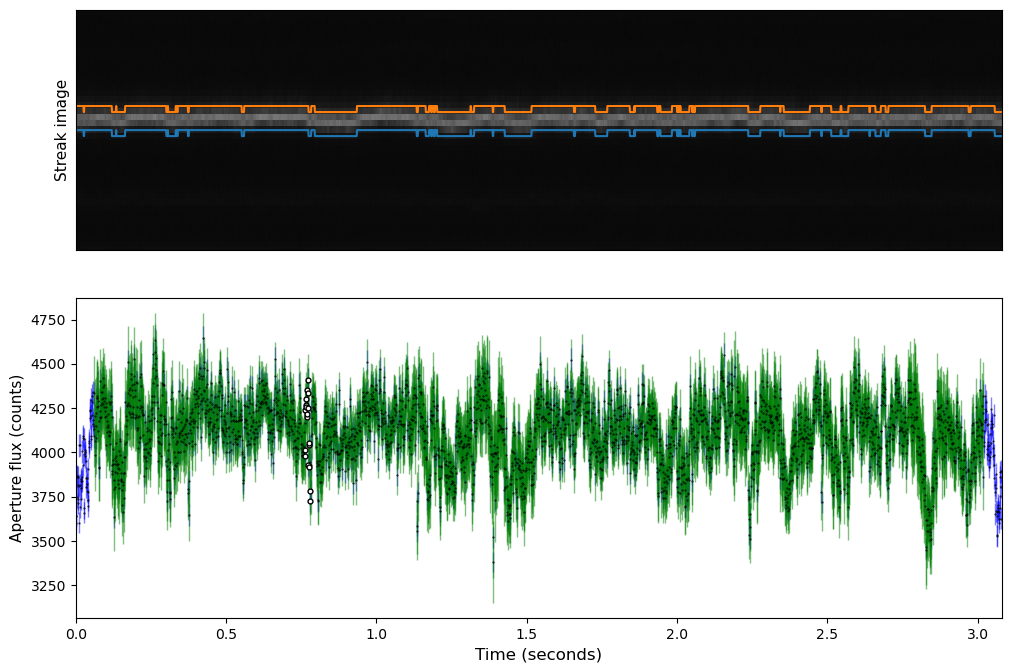

In [15]:
plot_tracking_wide(nocrs, 10, '1020', wideval=2)

<ErrorbarContainer object of 3 artists>

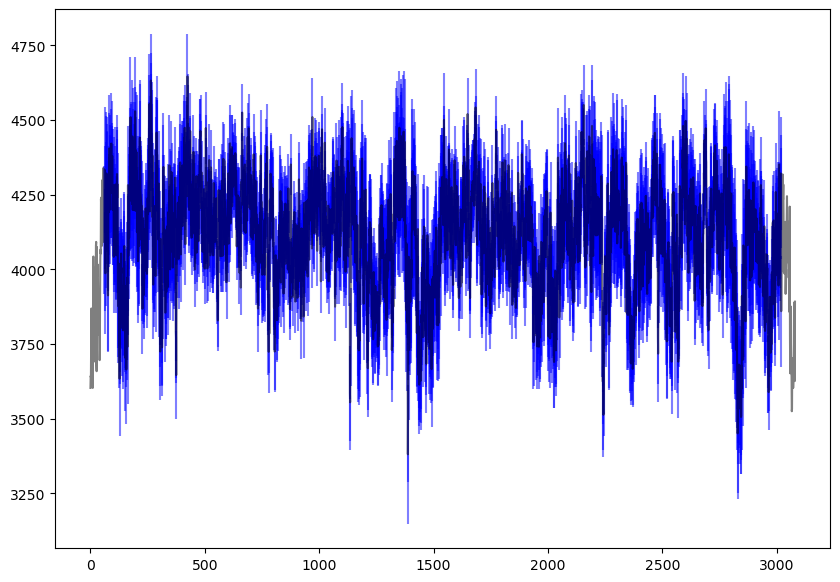

In [39]:
tot = get_tot(nocrs, 10, '1020', half_aperture=2)
stdvs, stderr = get_stdvs(tot)
plt.errorbar(np.linspace(0,len(tot), len(tot+1)),tot, yerr=stderr, color="black", ecolor='blue',alpha=.5)

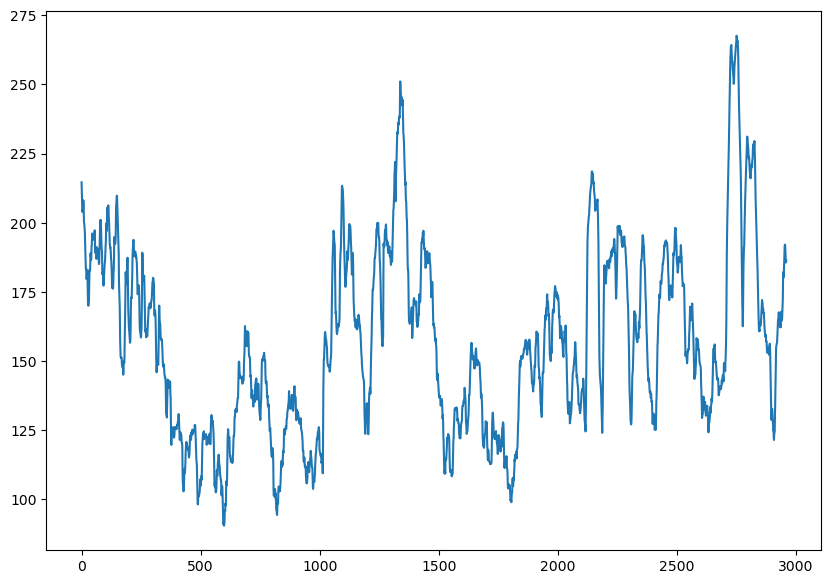

In [40]:
plt.plot(stdvs)

In [41]:
len(nocrs)

610903

In [ ]:
tot = get_tot(nocrs, 10, '1020', half_aperture=2)
stdvs, stderr = get_stdvs(tot)
plt.errorbar(np.linspace(0,len(tot), len(tot+1)),tot, yerr=stderr, color="black", ecolor='blue',alpha=.5)

In [61]:
tot = get_tot(nocrs, 10, '1020', half_aperture=2)
stds_one = get_stdvs(tot, do_all=False, df=nocrs, index=10)

In [62]:
stds_one

144.8363849314115

In [57]:
np.random.seed(42)
x = [np.random.randint(0, len(nocrs)+1) for p in range(0, 100)]

In [151]:
avstds_2_tracking = np.zeros(len(x))
avgbrightness_2_tracking = np.zeros(len(x))
avg_2_tracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=2, tracking=True)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_2_tracking[i] = np.average(tot)
    avstds_2_tracking[i] = avstd
    avg_2_tracking[i] = avstd/np.average(tot)

In [78]:
print(np.average(avstds_2), np.average(avgbrightness))
print(np.average(avstds_1_tracking), np.average(avgbrightness_1_tracking))
print(np.average(avstds_1_notracking), np.average(avgbrightness_1_notracking))
print(np.average(avstds_2_notracking), np.average(avgbrightness_2_notracking))


314.0068654447457 12413.093735399218
421.6098775928842 10473.762656683586
419.2493368463906 10153.474892521253
296.01817296506823 12316.165302535514


In [163]:
print("ap 2 no tracking, average of stdv/mean: ", np.average(avg_2_notracking))
print("stdv of that array: ", np.std(avg_2_notracking))
print("\n")
print("ap 1 no tracking, average of stdv/mean: ", np.average(avg_1_notracking))
print("stdv of that array: ", np.std(avg_1_notracking))
print("\n")
print("ap 2 with tracking, average of stdv/mean: ", np.average(avg_2_tracking))
print("stdv of that array: ", np.std(avg_2_tracking))
print("\n")
print("ap 1 with tracking, average of stdv/mean: ", np.average(avg_1_tracking))
print("stdv of that array: ", np.std(avg_1_tracking))

ap 2 no tracking, average of stdv/mean:  0.02496570553533173
stdv of that array:  0.005010229053188529


ap 1 no tracking, average of stdv/mean:  0.039628273794688675
stdv of that array:  0.01290549675962654


ap 2 with tracking, average of stdv/mean:  0.026151476859992816
stdv of that array:  0.008341975072050098


ap 1 with tracking, average of stdv/mean:  0.038729680398240984
stdv of that array:  0.013051221144692482


In [67]:
tot, maxcol = get_tot(nocrs, x[0], '1020', half_aperture=1, tracking=True)

In [69]:
stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=x[0])

In [71]:
np.average(stdvs)

436.5213114629762

In [147]:
avstds_1_tracking = np.zeros(len(x))
avgbrightness_1_tracking = np.zeros(len(x))
avg_1_tracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=1, tracking=True)
    avstd = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avgbrightness_1_tracking[i] = np.average(tot)
    avstds_1_tracking[i] = avstd
    avg_1_tracking[i] = avstd/np.average(tot)

In [ ]:
avstds_2_notracking = np.zeros(len(x))
avgbrightness_2_notracking = np.zeros(len(x))
avg_2_notracking  = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=2, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_2_notracking[i] = np.average(tot)
    avstds_2_notracking[i] = avstd
    avg_2_notracking[i] = avstd/np.average(tot)

In [ ]:
avstds_1_notracking = np.zeros(len(x))
avgbrightness_1_notracking = np.zeros(len(x))
avg_1_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot, maxcol = get_tot(nocrs, index, '1020', half_aperture=1, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstd = np.average(stdvs)
    avgbrightness_1_notracking[i] = np.average(tot)
    avstds_1_notracking[i] = avstd
    avg_1_notracking[i] = avstd/np.average(tot)

In [141]:
print(np.average(avstds_short_2))
print(np.average(avstds_short_1))

308.17053803360284
396.86827376370604


In [145]:
print(np.average(avstds_short_2_notracking))
print(np.average(avstds_short_1_notracking))

304.22124716929267
417.68214126143806


In [142]:
avstds_short_2_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot = get_tot(nocrs, index, '1020', half_aperture=2, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstds_short_2_notracking[i] = stdvs


In [144]:
avstds_short_1_notracking = np.zeros(len(x))
for i, index in enumerate(x):
    tot = get_tot(nocrs, index, '1020', half_aperture=1, tracking=False)
    stdvs = get_stdvs(tot, do_all=False, df=nocrs, index=index)
    avstds_short_1_notracking[i] = stdvs

In [131]:
tot = get_tot(nocrs, 10, '1020', half_aperture=2, tracking=False)

In [132]:
tot_tr = get_tot(nocrs, 10, '1020', half_aperture=2, tracking=True)

In [134]:
get_stdvs(tot, do_all=False, df=nocrs, index=index)

138.12097103524164

In [135]:
get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)

142.37083632115048

In [136]:
half_aperture = 2
tot = get_tot(nocrs, 10, '1020', half_aperture=half_aperture, tracking=False)
tot_tr = get_tot(nocrs, 10, '1020', half_aperture=half_aperture, tracking=True)
stdv_notr = get_stdvs(tot, do_all=False, df=nocrs, index=index)
stdv_tr = get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)
print('for aperture ', 2*half_aperture+1)
print('with tracking, stdv of ', stdv_tr)
print('without tracking, stdv of ', stdv_notr)

for aperture  5
with tracking, stdv of  142.37083632115048
without tracking, stdv of  138.12097103524164


In [137]:
half_aperture = 1
tot = get_tot(nocrs, 10, '1020', half_aperture=half_aperture, tracking=False)
tot_tr = get_tot(nocrs, 10, '1020', half_aperture=half_aperture, tracking=True)
stdv_notr = get_stdvs(tot, do_all=False, df=nocrs, index=index)
stdv_tr = get_stdvs(tot_tr, do_all=False, df=nocrs, index=index)
print('for aperture ', 2*half_aperture+1)
print('with tracking, stdv of ', stdv_tr)
print('without tracking, stdv of ', stdv_notr)

for aperture  3
with tracking, stdv of  167.4751852112393
without tracking, stdv of  160.46653922834994


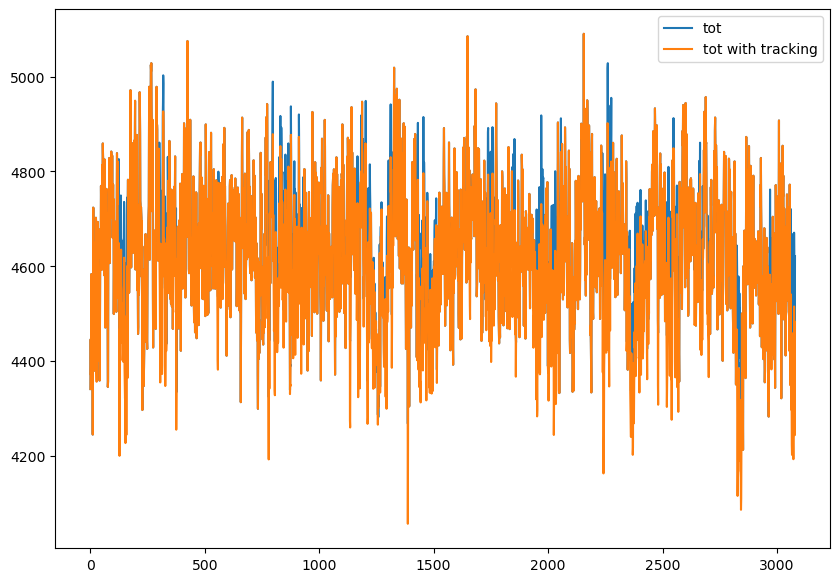

In [133]:
plt.plot(tot, label="tot")
plt.plot(tot_tr, label='tot with tracking')
plt.legend()

In [167]:
get_tot?

Signature: get_tot(df, index, direcname, half_aperture, tracking=True)
Docstring:     
File:      /tmp/ipykernel_32313/1241571390.py
Type:      function

In [168]:
tot, maxcols = get_tot(nocrs, 100, '1020', half_aperture=8, tracking=True)

In [170]:
tot2, maxcols = get_tot(nocrs, 100, '1020', half_aperture=3, tracking=True)

In [176]:
np.average(get_stdvs(tot))


469.0570444877958

In [177]:
np.average(get_stdvs(tot2))

479.25351151921257

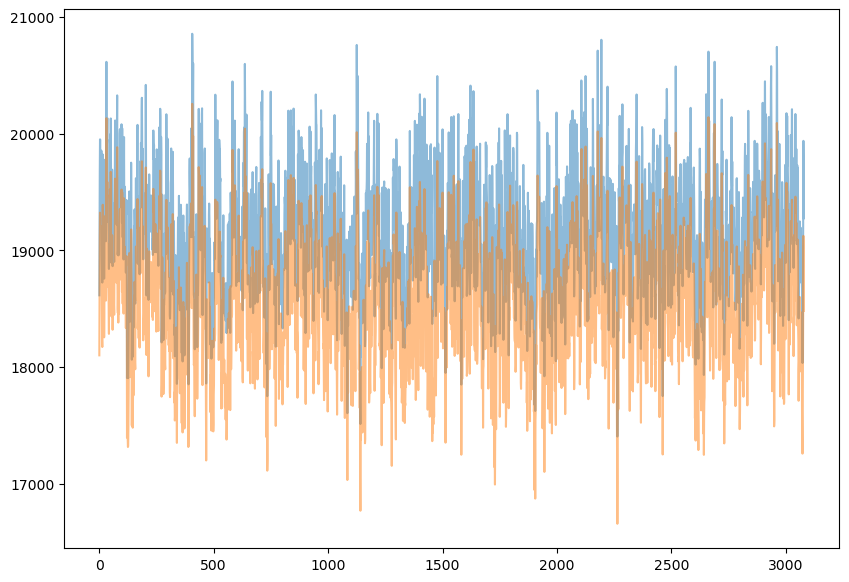

In [171]:
plt.plot(tot, alpha=.5)
plt.plot(tot2, alpha=.5)

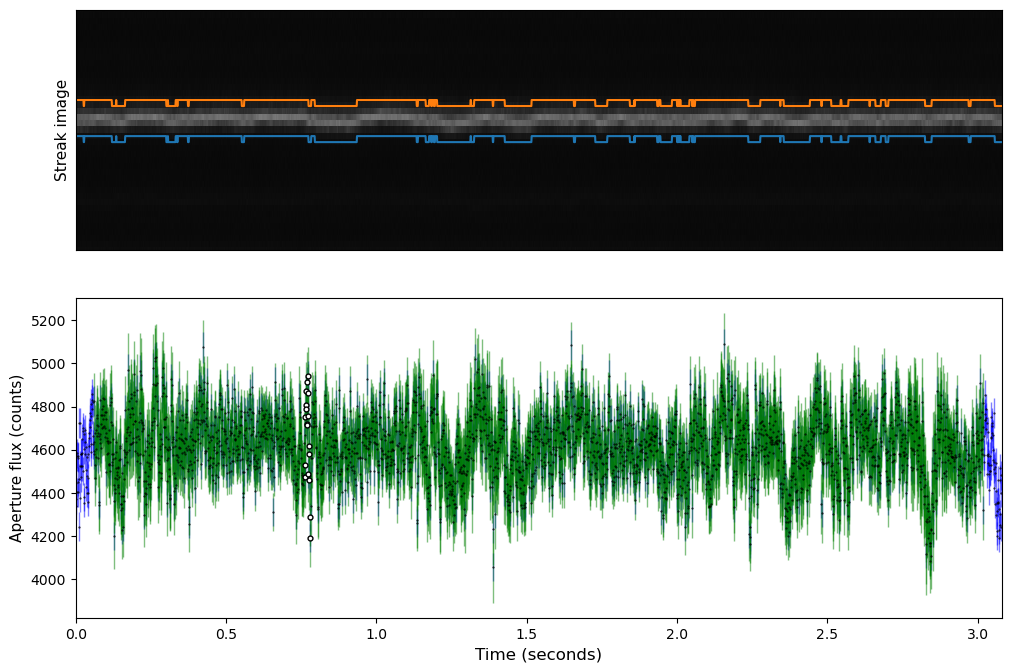

In [92]:
plot_tracking_wide(nocrs, 10, '1020', wideval=3)

In [143]:
get_stdvs(tot, do_all=False, df=nocrs, index=100)

508.9162103411305

In [142]:
get_stdvs(filtered_tot, do_all=False, df=nocrs, index=100)

504.02674689504215

In [191]:
peakindex = 0


(0.0, 500.0)

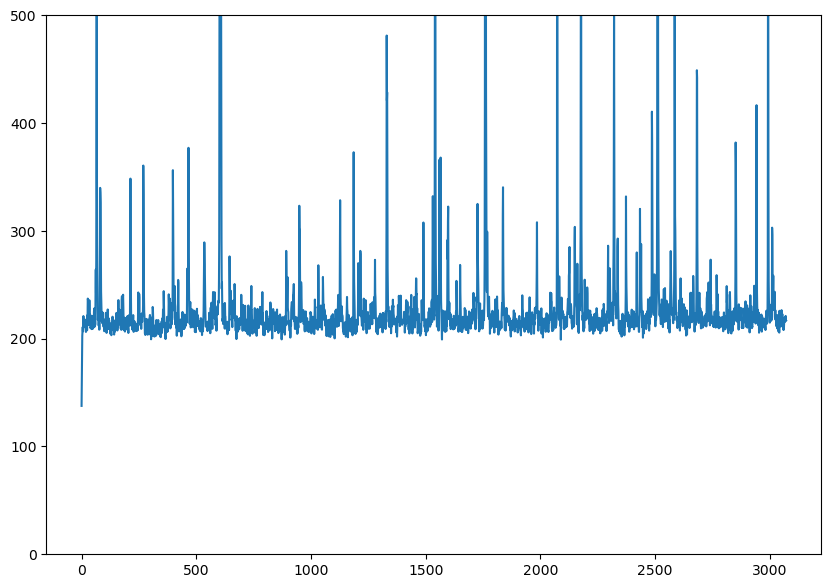

In [183]:
plt.plot(image[1000,:])
plt.ylim(0,500)

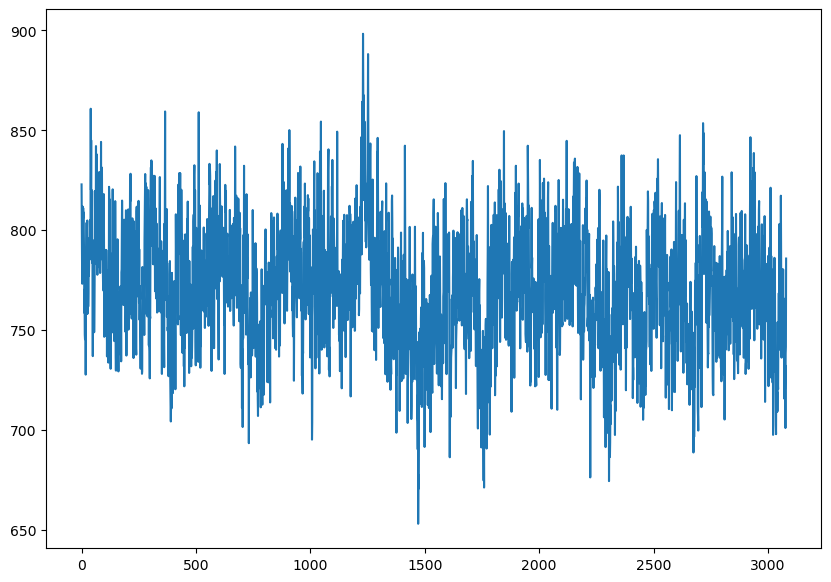

In [192]:
plt.plot(tot2)

In [184]:
peaks, _ = find_peaks(image[1000,:], height=500)  # Adjust height threshold for your data

In [185]:
peaks

array([  66,  604, 1541, 1760, 2073, 2177, 2321, 2511, 2585, 2993])

In [198]:
all_streaks = []
for i in range(len(peaks)):
    tot = get_tot_streak(i)
    all_streaks.append(tot)

In [199]:
np.shape(all_streaks)

(10, 3080)

In [104]:
nocrs.iloc[100]

Unnamed: 0.2                                           100
Unnamed: 0.1                                           576
Unnamed: 0                                             576
filename          ztf_20221020154120_000640_zi_c09_x_0017.
type                                                   neg
row_from_nn                                         1217.0
col_from_nn                                          590.0
detection_size                                         5.0
quadrant                                                 4
sobel_ratio                                      18.305748
Name: 100, dtype: object

In [197]:
def get_tot_streak(peakindex):
    '''
    '''
    df=nocrs
    index=100
    direcname='1020'
    half_aperture=2
    tracking=False
    wideval = half_aperture
    wid=10
    fname = df.iloc[index]["filename"]+"fits.fz"
    row = int(df.iloc[index]["row_from_nn"])+10 #we add 10 here bc that's the cnn offset of returned values
    # col = int(df.iloc[index]["col_from_nn"])+10
    col = peaks[peakindex]
    quad= int(df.iloc[index]["quadrant"])
    column = int(col)

    fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
    path = fpath+fname
    hdul=fits.open(path)
    # print(path)
    file1_array = hdul[quad].data
    # norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
    image = file1_array

    background = rff.get_image_background(image)
    imagenobackground = image - np.full(np.shape(image),background)
    if tracking==False:
        zeropoint = col-7
        averages = np.average(imagenobackground[row-10:row+10, zeropoint:zeropoint+14], axis=0)
        maxind = np.argmax(averages)
        tot2 = np.zeros(imagenobackground.shape[0])
        for r in range(0, imagenobackground.shape[0]): #this should be each row, probably
            maxcol = zeropoint + maxind
            combined = imagenobackground[r, maxcol]
            for i in range(1,half_aperture+1):
                combined+=imagenobackground[r, maxcol-i]
                combined+=imagenobackground[r, maxcol+i]
            tot2[r] = combined

    #so we need to track the whole streak
    #for each row, need to choose a column index
    tot = np.zeros(imagenobackground.shape[0])
    maxcols = np.zeros(imagenobackground.shape[0])
    zeropoint = col-10
    for r in range(0, imagenobackground.shape[0]): #this should be each row, probably
        maxcol = np.argmax(imagenobackground[r, zeropoint:zeropoint+20])+ zeropoint
        maxcols[r] = maxcol
        combined = imagenobackground[r, maxcol]
        for i in range(1,half_aperture+1):
            combined+=imagenobackground[r, maxcol-i]
            combined+=imagenobackground[r, maxcol+i]
        # combined = imagenobackground[r, maxcol-2] + imagenobackground[r, maxcol-1] + imagenobackground[r, maxcol] + imagenobackground[r, maxcol+1] + imagenobackground[r, maxcol+2]
        # print(combined)
        tot[r] = combined


    

    return tot

In [ ]:
tot, maxcols = get_tot(nocrs,100, '1020',  half_aperture=2, tracking=True)

In [76]:
def get_filtered_fft(tot, target_freq_ms):
    # Compute FFT and get frequencies

    # Step 1: Compute FFT and get frequencies
    Fs = 1  # Assuming pixel as unit for FFT frequency calculation
    N = len(tot)
    fft_vals = rfft(tot)
    freqs = rfftfreq(N, d=1/Fs)
    
    # Step 2: Convert frequencies to cycles per millisecond (mHz)
    pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
    freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms
    
    # Step 3: Define Gaussian band-stop filter parameters in mHz
    # target_freq_ms = .1549  # Target frequency in cycles per ms (replace with your specific value)
    sigma_ms = 0.0001  # Width of Gaussian in cycles per ms
    
    # Gaussian band-stop filter in cycles per ms
    gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms)**2)
    
    # Step 4: Apply the filter to FFT values
    filtered_fft_vals = fft_vals * gaussian_filter
    
    # Step 5: Inverse FFT to get the filtered signal back in time domain
    filtered_tot = irfft(filtered_fft_vals)
    
    return filtered_fft_vals, filtered_tot, freqs_ms

In [296]:
tot, maxcols = get_tot(nocrs,100, '1020',  half_aperture=2, tracking=True)

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


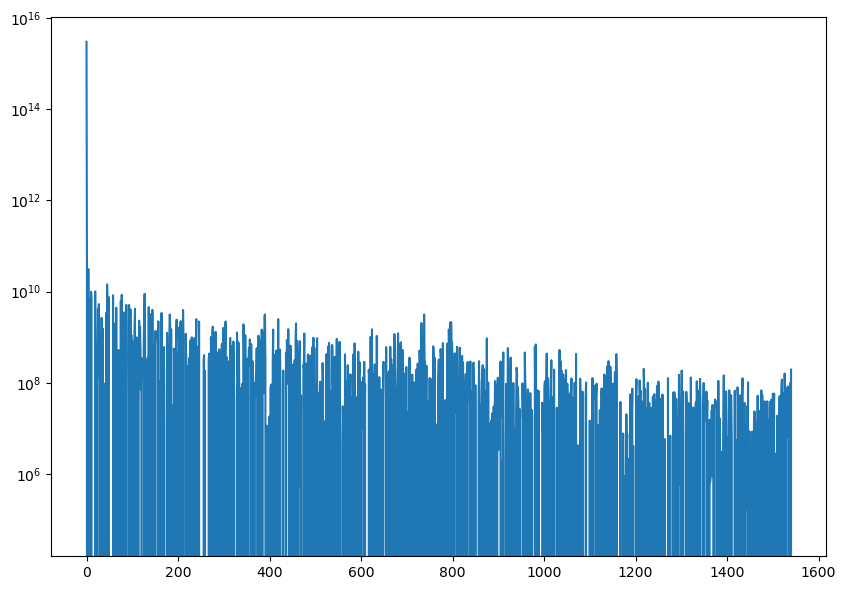

In [264]:


# Compute FFT and get frequencies
tot, maxcols = get_tot(nocrs,100, '1020',  half_aperture=2, tracking=True)




# Step 1: Compute FFT and get frequencies
Fs = 1  # Assuming pixel as unit for FFT frequency calculation
N = len(tot)
fft_vals = rfft(tot)
freqs = rfftfreq(N, d=1/Fs)

# Step 2: Convert frequencies to cycles per millisecond (mHz)
pixel_to_ms_factor = 0.6  # 0.6 pixels per millisecond
freqs_ms = freqs * pixel_to_ms_factor  # Now in cycles per ms

# Step 3: Define Gaussian band-stop filter parameters in mHz
target_freq_ms = .1549  # Target frequency in cycles per ms (replace with your specific value)
sigma_ms = 0.0001  # Width of Gaussian in cycles per ms

# Gaussian band-stop filter in cycles per ms
gaussian_filter = 1 - np.exp(-0.5 * ((freqs_ms - target_freq_ms) / sigma_ms)**2)

# Step 4: Apply the filter to FFT values
filtered_fft_vals = fft_vals * gaussian_filter

# Step 5: Inverse FFT to get the filtered signal back in time domain
filtered_tot = irfft(filtered_fft_vals)

# Plot the original and filtered signals for comparison
# plt.plot(tot, label='Original Signal')
# plt.plot(filtered_tot, label='Filtered Signal', linestyle='--')
# plt.legend()
# plt.xlabel("Pixel Index")
# plt.ylabel("Flux")
# plt.title("Original vs. Gaussian-Filtered Signal")
# plt.show()

# plt.plot(filtered_fft_vals)
plt.plot(np.square(fft_vals))
plt.yscale("log")

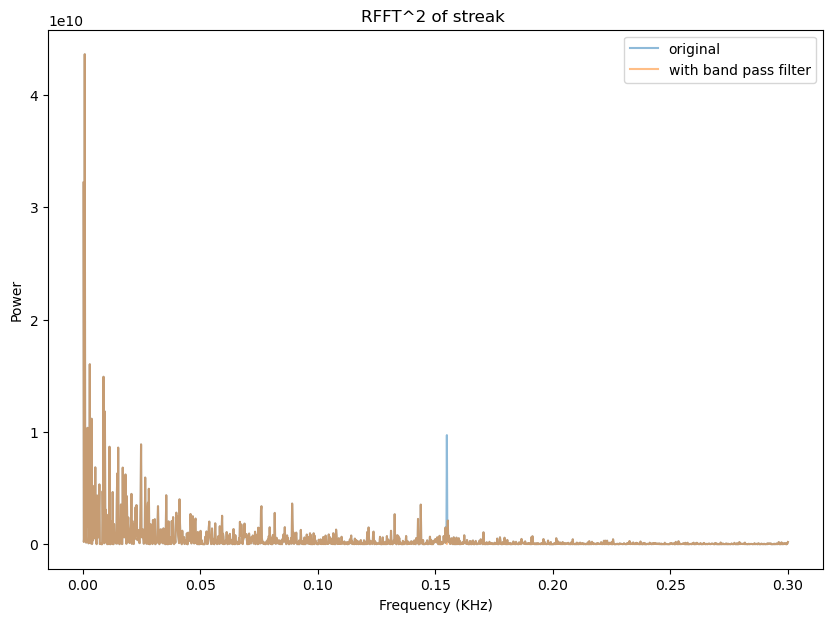

In [265]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))

filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(tot, target_freq_ms=.1549)


sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1/Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label='with band pass filter', alpha=.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)") #cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

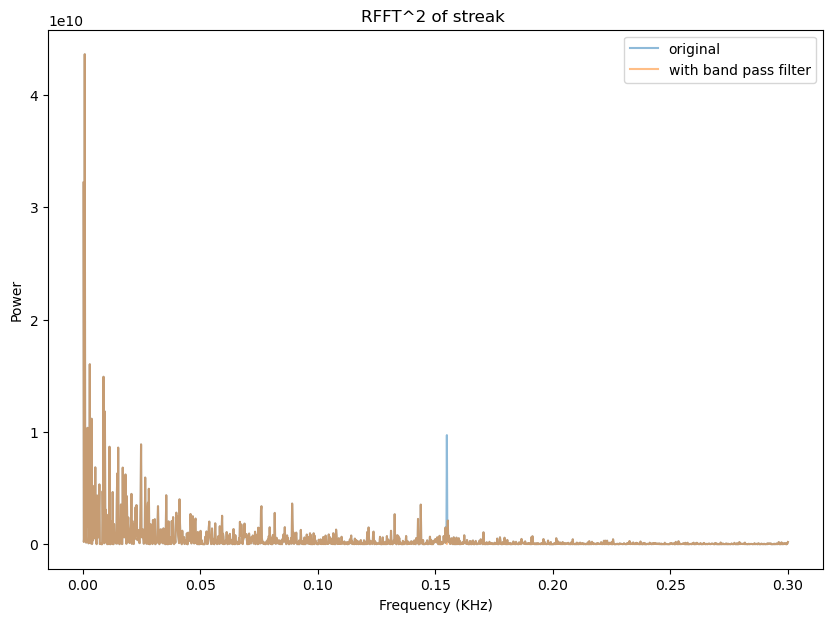

In [159]:
sqfft = np.square(np.real(np.fft.rfft(tot)[1:]))
sqfft_filtered = np.square(np.real(np.fft.rfft(filtered_tot)[1:]))
Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
N = len(tot)
freqs = np.fft.rfftfreq(N, d=1/Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

plt.plot(freqs_ms[1:], sqfft, label="original", alpha=.5)
plt.plot(freqs_ms[1:], sqfft_filtered, label='with band pass filter', alpha=.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)") #cycles per millisecond
plt.title("RFFT^2 of streak ")
plt.legend()
# plt.yscale("log")

In [207]:
all_streaks[2]

array([1652.83117676, 1589.03283691, 1586.10839844, ..., 1671.83349609,
       1667.06005859, 1638.4185791 ])

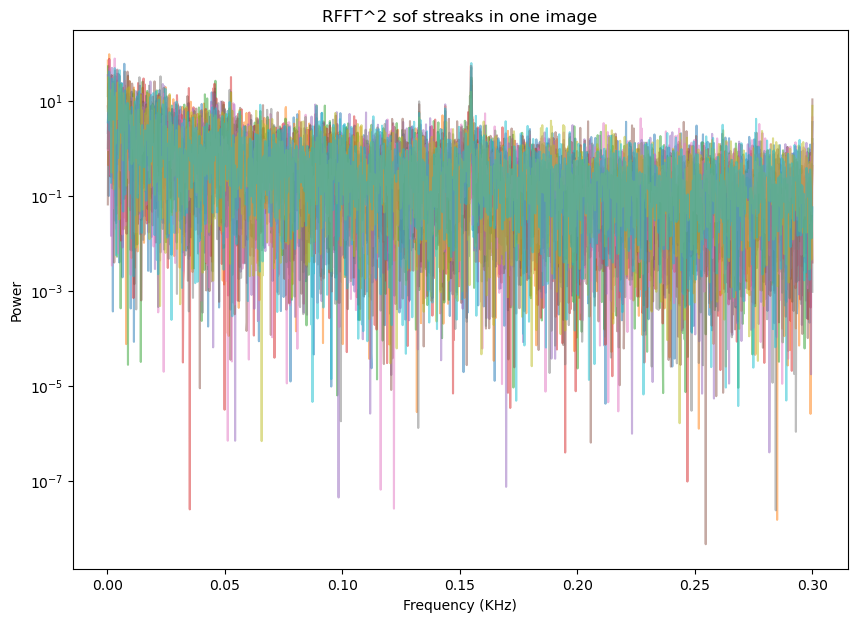

In [220]:
sqffts = []
freqsms = []
divideds = []
for streak in all_streaks:
    sqfft = np.square(np.real(np.fft.rfft(streak)[1:]))
    mean = np.average(sqfft)
    divided = sqfft/mean
    sqffts.append(sqfft)
    divideds.append(divided)
    Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
    N = len(tot)
    freqs = np.fft.rfftfreq(N, d=1/Fs)
    
    pixel_to_ms_factor = 1 / 0.6
    freqs_ms = freqs / pixel_to_ms_factor
    freqsms.append(freqs_ms)
    
    plt.plot(freqs_ms[1:], divided, alpha=.5)
    plt.ylabel("Power")
    plt.xlabel("Frequency (KHz)") #cycles per millisecond
    plt.title("RFFT^2 sof streaks in one image")
    # plt.legend()
    plt.yscale("log")

In [225]:
len(divideds)

10

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


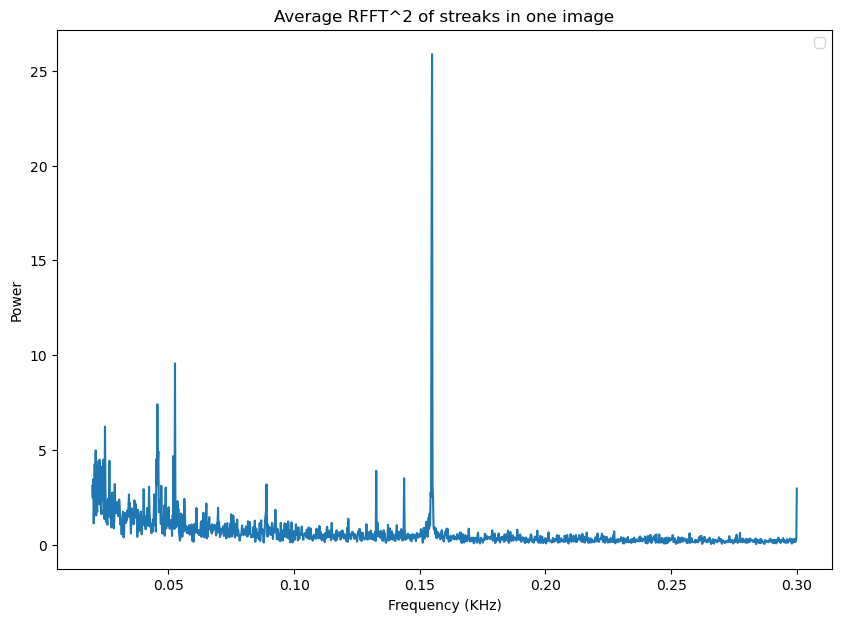

In [258]:

plt.plot(freqs_ms[1:][100:], np.average(divideds, axis=0)[100:])
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)") #cycles per millisecond
plt.title("Average RFFT^2 of streaks in one image")
plt.legend()
# plt.yscale("log")
# plt.xscale("log")
# plt.xlim(0.01, .056)

In [254]:
avgs = np.average(divideds, axis=0)

In [259]:
peaks_ft, _ = find_peaks(avgs[100:], height=5)  # Adjust height threshold for your data

In [260]:
peaks_ft

array([ 26, 133, 169, 694])

In [266]:
filtered_tot = tot
for peak in peaks_ft:
    allfreqms = freqs_ms[101:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(filtered_tot, target_freq_ms=tofilter)
    

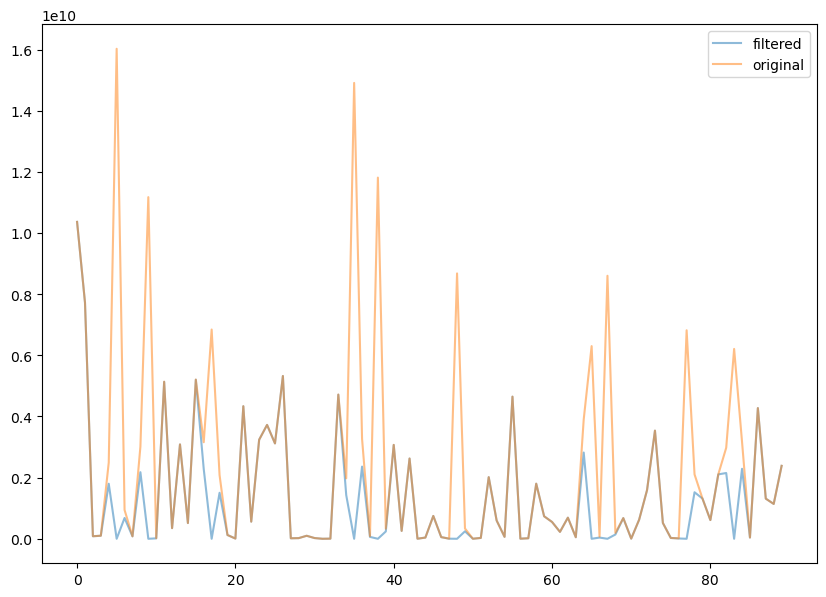

In [288]:
plt.plot(np.square(np.real(np.fft.rfft(filtered_tot)[10:100])), label='filtered', alpha=.5)
plt.plot(np.square(np.real(np.fft.rfft(tot)[10:100])), label='original', alpha=.5)
plt.legend()

In [284]:
peaks_ft2, _ = find_peaks(np.square(np.real(np.fft.rfft(filtered_tot)[10:100])), height=.6e10) 

In [287]:
peaks_ft2

array([ 5,  9, 17, 35, 38, 48, 65, 67, 77, 83])

In [298]:
filtered_tot = tot
for peak in peaks_ft2:
    allfreqms = freqs_ms[10:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(filtered_tot, target_freq_ms=tofilter)

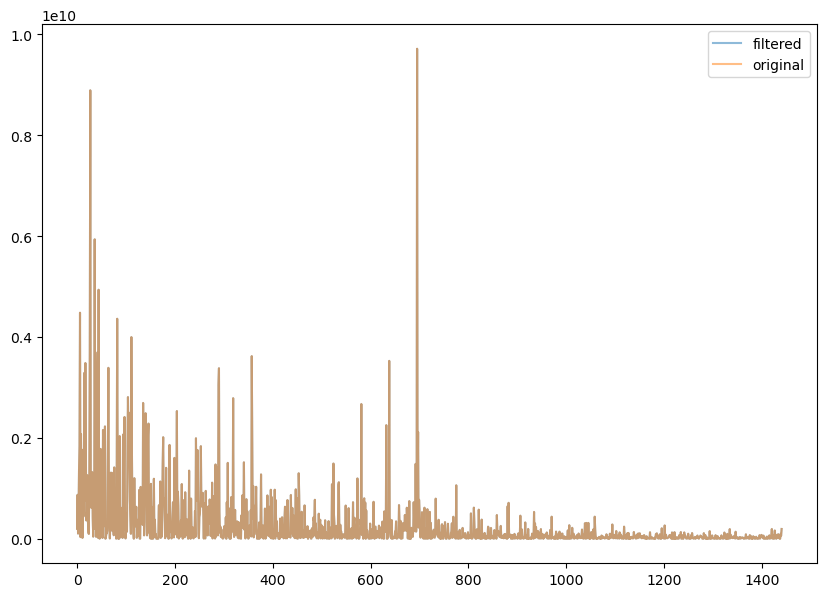

In [297]:
plt.plot(np.square(np.real(np.fft.rfft(filtered_tot)[100:])), label='filtered', alpha=.5)
plt.plot(np.square(np.real(np.fft.rfft(tot)[100:])), label='original', alpha=.5)
plt.legend()

In [300]:
peaks_ft3, _ = find_peaks(np.square(np.real(np.fft.rfft(filtered_tot)[100:])), height=.3e10) 

In [301]:
for peak in peaks_ft3:
    allfreqms = freqs_ms[100:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(filtered_tot, target_freq_ms=tofilter)

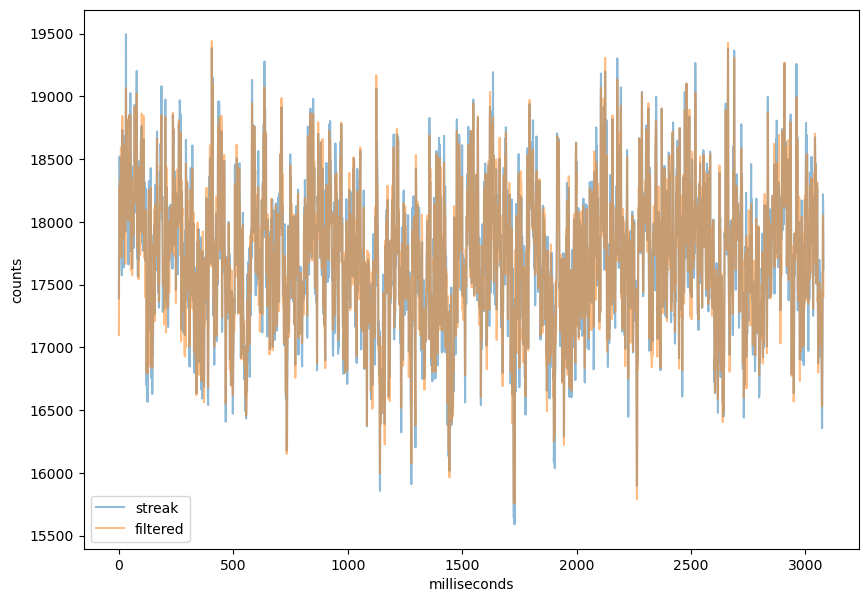

In [315]:
plt.plot(tot, label='streak', alpha=.5)
plt.plot(filtered_tot, label='filtered', alpha=.5)
# plt.xlim(100,200)
plt.xlabel('milliseconds')
plt.ylabel("counts")
plt.legend()

In [316]:
peaks_ft4, _ = find_peaks(np.square(np.real(np.fft.rfft(filtered_tot)[1:])), height=.2e10) 

In [317]:
peaks_ft4

array([  3,   7,   9,  14,  18,  20,  22,  24,  26,  30,  33,  35,  42,
        44,  47,  49,  51,  57,  61,  64,  74,  76,  82,  86,  92,  95,
        98, 107, 125, 140, 152, 156, 186, 193, 196, 203, 205, 234, 239,
       245, 275, 303, 388, 418, 680, 731, 796])

In [318]:
for peak in peaks_ft4:
    allfreqms = freqs_ms[1:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(filtered_tot, target_freq_ms=tofilter)

In [319]:
np.average(get_stdvs(filtered_tot))

399.78746308990543

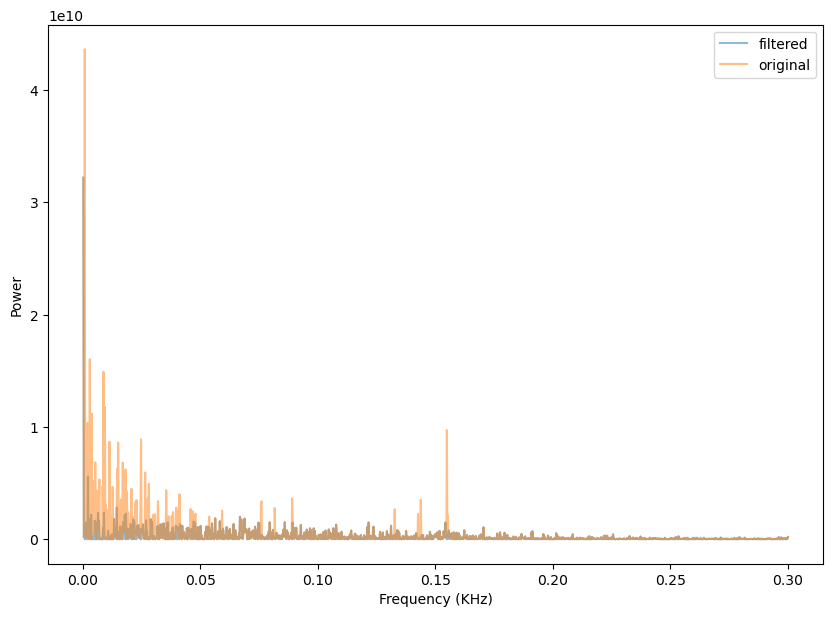

In [329]:
plt.plot(freqs_ms[1:], np.square(np.real(np.fft.rfft(filtered_tot)[1:])), label='filtered', alpha=.5)
plt.plot(freqs_ms[1:], np.square(np.real(np.fft.rfft(tot)[1:])), label='original', alpha=.5)
plt.ylabel("Power")
plt.xlabel("Frequency (KHz)") #cycles per millisecond
# plt.title("Average RFFT^2 of streaks in one image")
plt.legend()

Text(0.5, 1.0, 'Streak and streak after fourier filtering')

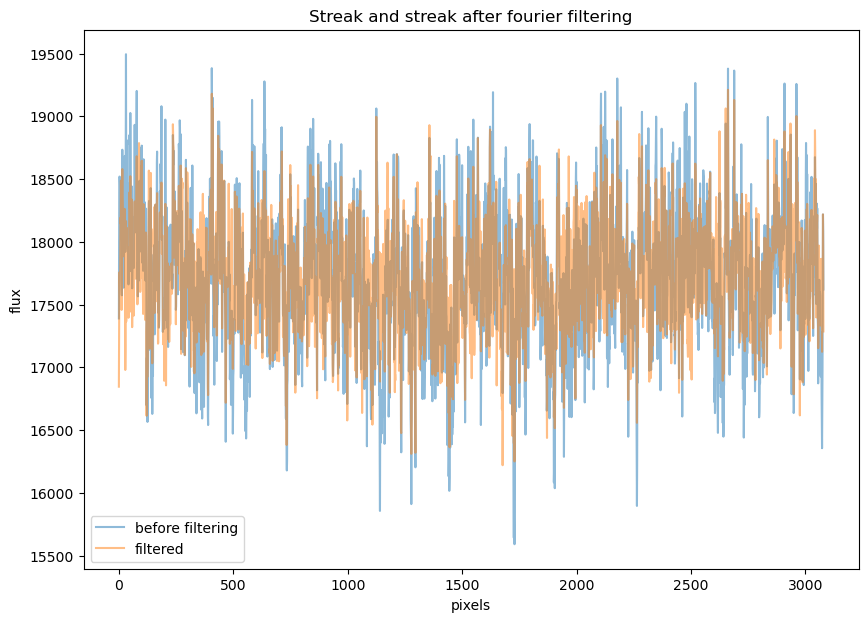

In [328]:
plt.plot( tot, label='before filtering', alpha=.5)
plt.plot(filtered_tot, label='filtered', alpha=.5)
# plt.ylabel("Power")
# plt.xlabel("Frequency (KHz)") #cycles per millisecond
# plt.title("Average RFFT^2 of streaks in one image")
plt.legend()
# plt.yscale("log")
# plt.xscale("log")
# plt.xlim(0.01, .056)
plt.xlabel("pixels")
plt.ylabel("flux")
plt.title("Streak and streak after fourier filtering")

In [32]:
rff.get_milliseconds_from_khz(.3)

(3.3333333333333335, 0.0033333333333333335, 2.0)

In [ ]:
'''
so if we implant a gaussian in tot, can we retrieve iit?
'''

In [43]:
tot2, otherthing = rff.get_tot(nocrs, 10, '1020', half_aperture=2, tracking=False)

In [38]:
imp.gaussian_event?

Signature: imp.gaussian_event(ys, M, sig, A, original_values)
Docstring:
ys should be the array of y values
#m is the center y value
#sig is the standard deviation
#original_values is the original brightness (for each y value)
#A is the maximum brightening. A-1 is in the code bc of that additional 1 later
#return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
File:      ~/implantation_functions.py
Type:      function

In [42]:
tot2

(array([4341.06591797, 4445.94482422, 4370.66210938, ..., 4546.61425781,
        4371.90234375, 4621.49902344]),
 array([2511, 2511, 2511, ..., 2511, 2511, 2511]))

In [54]:
np.linspace(0, len(tot2)-1, len(tot2))

array([0.000e+00, 1.000e+00, 2.000e+00, ..., 3.077e+03, 3.078e+03,
       3.079e+03])

In [60]:
ys = np.linspace(0, len(tot2)-1, len(tot2))
M = 1000
sig = 3
A = 1.5
original_values = tot2

gaussianed_streak = imp.gaussian_event(ys, M, sig, A, original_values)

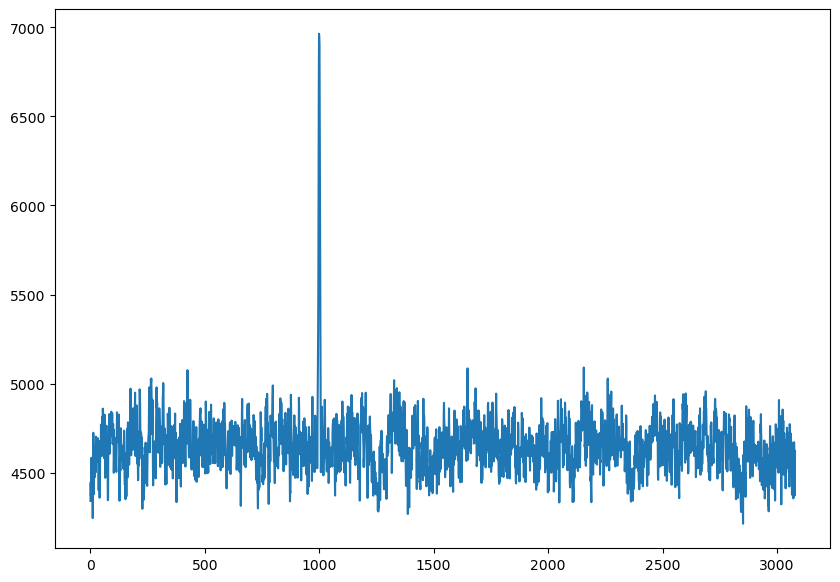

In [61]:
plt.plot(gaussianed_streak)

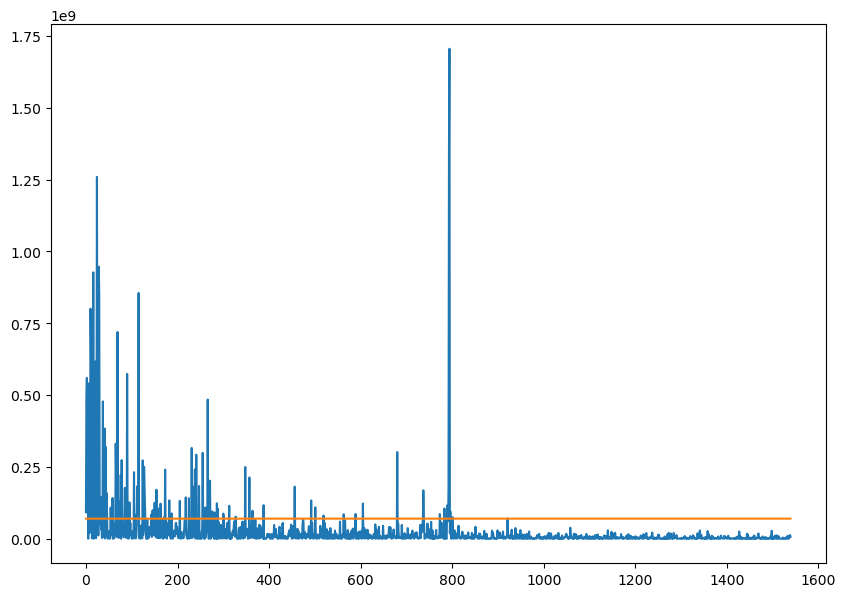

In [91]:
plt.plot(np.square(np.real(np.fft.rfft(tot2)[1:])))
plt.plot(np.full(len(np.square(np.real(np.fft.rfft(tot2)[1:]))), .07e9))

In [92]:
peaks_ft4, _ = find_peaks(np.square(np.real(np.fft.rfft(tot2)[1:])), height=.07e9) 

In [74]:
Fs = 1 #change this if i want to change the sampling rate - right now, it's pixels
N = len(tot2)
freqs = np.fft.rfftfreq(N, d=1/Fs)

pixel_to_ms_factor = 1 / 0.6
freqs_ms = freqs / pixel_to_ms_factor

In [93]:
filtered_tot = gaussianed_streak
for peak in peaks_ft4:
    allfreqms = freqs_ms[1:]
    tofilter = allfreqms[peak]

    filtered_fft_vals, filtered_tot, freqs_ms = get_filtered_fft(filtered_tot, target_freq_ms=tofilter)

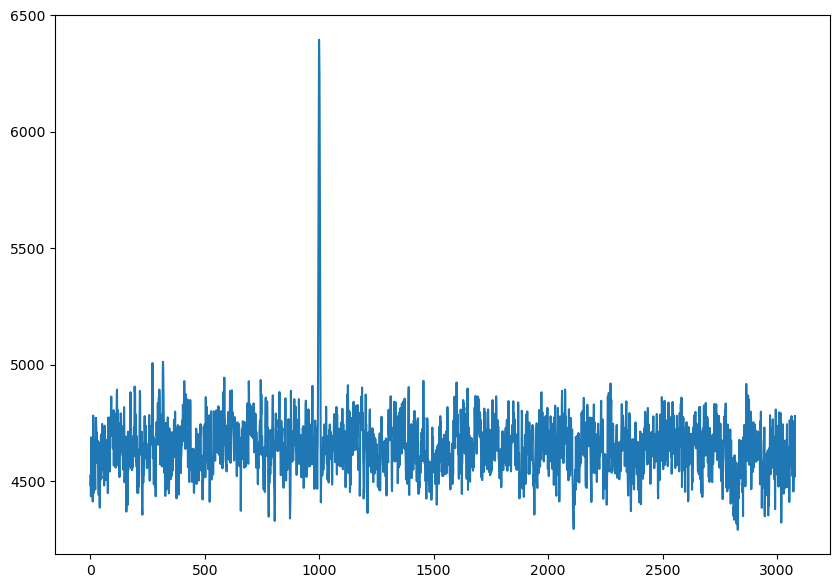

In [94]:
plt.plot(filtered_tot)

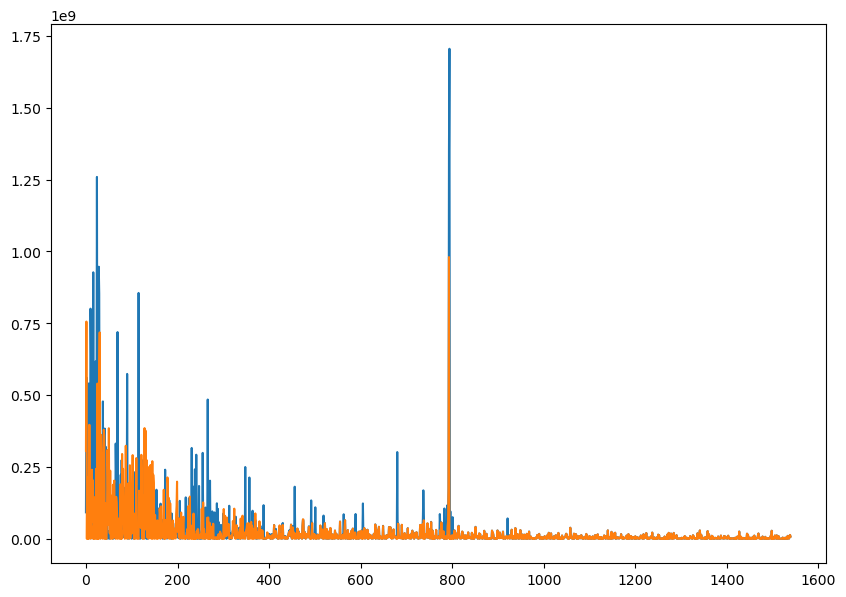

In [95]:
plt.plot(np.square(np.real(np.fft.rfft(tot2)[1:])))
plt.plot(np.square(np.real(np.fft.rfft(filtered_tot)[1:])))

In [99]:
rff.get_stdvs(filtered_tot)[61:-60]

array([110.75702262, 110.76667158, 108.96162787, ...,  96.33159753,
        97.59986013,  98.02605118])

In [100]:
np.mean(rff.get_stdvs(filtered_tot)[61:-60])

110.32437320798175

In [102]:
np.mean(rff.get_stdvs(gaussianed_streak)[61:-60])

137.36084071660557

In [ ]:
'''
so what we've learned from this is that you can extract transients after 
cutting out a fuck ton of spikes in the fourier transform,
but an absolute threshold is not a useful way to do that

ugh riley's method...
'''